# What drives success in crowdfunding campaigns?
FINA 4930 — Mini Project 1

**Goal:** predict the fraction of the funding goal reached (`frac_raised`) with regression models, choose a model that is
appropriate for a small sample (n = 439), and interpret which campaign features matter.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import (train_test_split, KFold, GroupKFold, RepeatedKFold, GridSearchCV,
                                     cross_validate, learning_curve, validation_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, HuberRegressor, lasso_path
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
FIG, RES = "figures", "results"

## 1. Data

In [2]:
raw_all = pd.read_excel("data/crowdfunding_campaign.xlsx", sheet_name="Sheet1").dropna(how="all")
dictionary = pd.read_excel("data/crowdfunding_campaign.xlsx", sheet_name="Sheet2", header=1)
print(raw_all.shape)
display(dictionary)
display(raw_all.head())

(439, 11)


,cid,Campaign ID,Notes
0,pre_order_perk,Whether the campaign promises a product,Many crowdfunding campaigns promise to provide...
1,amt_goal,Goal amount for campaign,Dollar amount advertised by crowdfunding campa...
2,frac_raised,Fraction of goal raised,Fraction of goal investment amount raised in c...
3,tech_campaign,Technology campaign,Whether the campaign is for a technology product.
4,sbiz_campaign,Small business campaign,Whether the campaign is for a small business
5,fixed_fund,Fixed funding campaign - only raises when goal...,Founders are only paid the investment dollars ...
6,state,State,State of team raising capital
7,year_start,Campaign start year,Start year of campaign
8,iot_plus,"Product, if being funded, is an IoT or connect...",Internet of things devices are those that conn...
9,delivery,Product was delivered,Whether the product was eventually delivered.


,cid,pre_order_perk,amt_goal,frac_raised,tech_campaign,sbiz_campaign,fixed_fund,state,year_start,iot_plus,delivery
0,71762,0,2500,0.040000,0,1,0.0,Kentucky,2011,0.0,NaN
1,72367,0,1500,1.733333,0,0,0.0,Indiana,2012,0.0,NaN
2,73646,1,100000,1.007510,1,0,0.0,Louisiana,2012,0.0,NaN
3,74867,1,7000,0.000000,0,1,0.0,North Carolina,2012,0.0,NaN
4,82829,1,2000,1.000000,0,1,0.0,Pennsylvania,2011,0.0,NaN


### Effective sample size: duplicated campaigns
The sheet has 439 rows but `cid` (campaign ID) is not unique. Every repeated `cid` is an **exact copy** of the same
campaign (identical on all 11 columns), so the data contain far fewer independent observations than rows.

In [3]:
reps = raw_all.groupby("cid").size()
print("Rows:", len(raw_all), " unique campaigns:", raw_all.cid.nunique(), " exact duplicate rows:", raw_all.duplicated().sum())
print("Campaigns with conflicting values across copies:",
      int((raw_all.groupby("cid").nunique(dropna=False) > 1).any(axis=1).sum()))
print("\nCopies per campaign:\n", reps.value_counts().sort_index().to_string())
raw = raw_all.drop_duplicates().reset_index(drop=True)
print("\nAnalysis sample after de-duplication:", raw.shape)

Rows: 439  unique campaigns: 224  exact duplicate rows: 215
Campaigns with conflicting values across copies: 0

Copies per campaign:
 1     147
2      31
3      16
4      13
5       4
6       3
7       1
8       2
9       2
10      4
11      1

Analysis sample after de-duplication: (224, 11)


**Decision:** the main analysis uses the **224 unique campaigns**. Keeping the copies would (i) give some campaigns up to
11× the weight of others for no economic reason, (ii) shrink standard errors spuriously, and (iii) leak information in
cross-validation, since copies of one campaign land in both training and validation folds. Section 2b shows how
badly (iii) distorts model comparison.

In [4]:
display(raw.describe().T)
print("Missing values:\n", raw.isna().sum())
print("\nShare of campaigns with frac_raised = 0:", round((raw.frac_raised == 0).mean(), 3))
print("Share reaching their goal (frac_raised >= 1):", round((raw.frac_raised >= 1).mean(), 3))
print("Campaigns at the maximum value:", (raw.frac_raised == raw.frac_raised.max()).sum(), "at", raw.frac_raised.max())

,count,mean,std,min,25%,50%,75%,max
cid,224.0,165801.950893,41891.550675,71762.0,138008.250000,159915.0000,200380.75,256198.00000
pre_order_perk,224.0,0.491071,0.501040,0.0,0.000000,0.0000,1.00,1.00000
amt_goal,224.0,17412.232143,31524.139163,500.0,1262.500000,5000.0000,15000.00,200000.00000
frac_raised,224.0,1.749669,3.644054,0.0,0.005571,1.0145,1.75,25.91808
tech_campaign,224.0,0.459821,0.499499,0.0,0.000000,0.0000,1.00,1.00000
sbiz_campaign,224.0,0.415179,0.493856,0.0,0.000000,0.0000,1.00,1.00000
fixed_fund,219.0,0.214612,0.411493,0.0,0.000000,0.0000,0.00,1.00000
year_start,224.0,2012.651786,0.563618,2011.0,2012.000000,2013.0000,2013.00,2013.00000
iot_plus,221.0,0.117647,0.322921,0.0,0.000000,0.0000,0.00,1.00000
delivery,53.0,0.801887,0.384053,0.0,1.000000,1.0000,1.00,1.00000


Missing values:
 cid                 0
pre_order_perk      0
amt_goal            0
frac_raised         0
tech_campaign       0
sbiz_campaign       0
fixed_fund          5
state               0
year_start          0
iot_plus            3
delivery          171
dtype: int64

Share of campaigns with frac_raised = 0: 0.228
Share reaching their goal (frac_raised >= 1): 0.612
Campaigns at the maximum value: 1 at 25.91808


### Exploratory plots

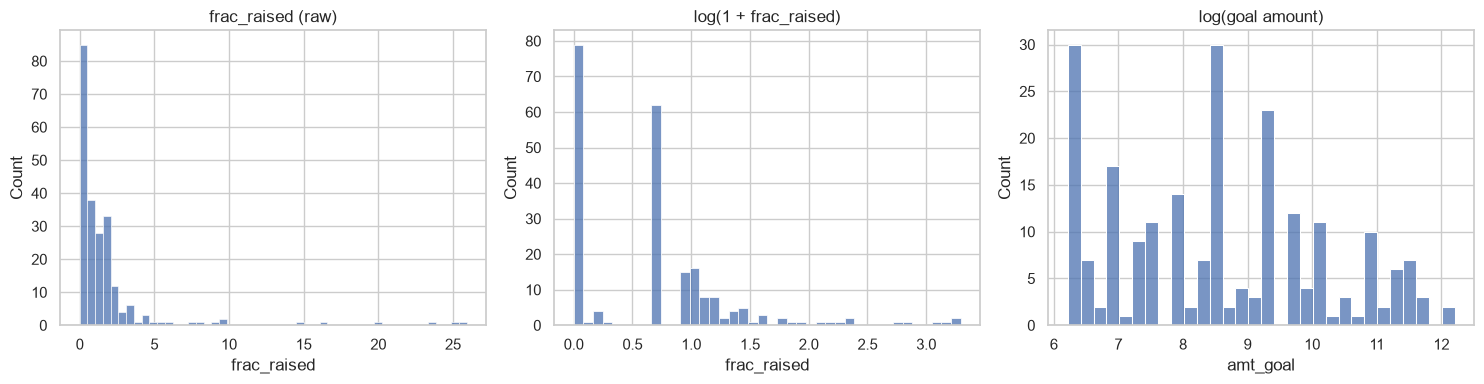

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(raw.frac_raised, bins=50, ax=ax[0]); ax[0].set_title("frac_raised (raw)")
sns.histplot(np.log1p(raw.frac_raised), bins=40, ax=ax[1]); ax[1].set_title("log(1 + frac_raised)")
sns.histplot(np.log(raw.amt_goal), bins=30, ax=ax[2]); ax[2].set_title("log(goal amount)")
plt.tight_layout(); plt.savefig(f"{FIG}/01_distributions.png", dpi=150); plt.show()

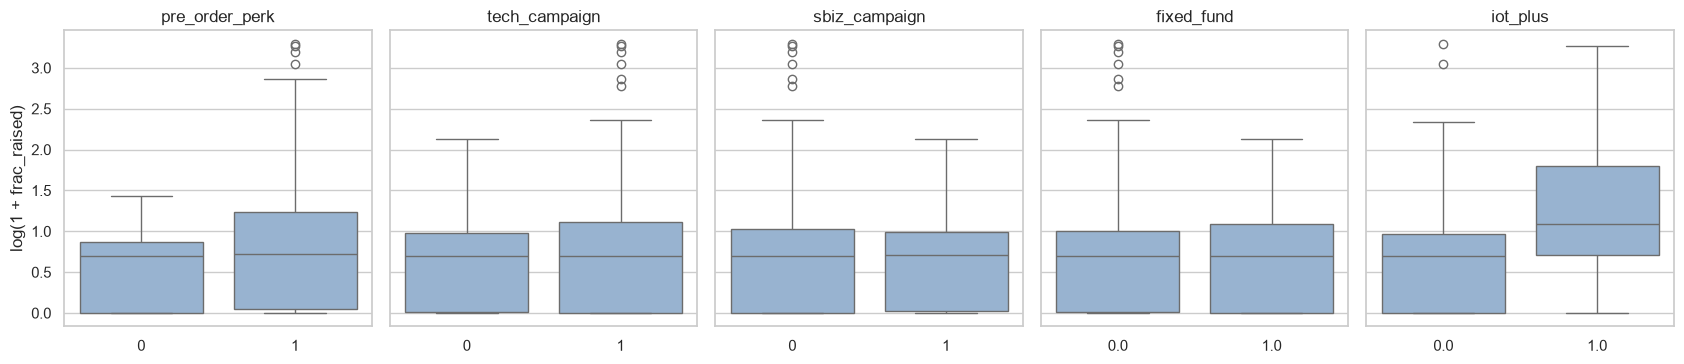

In [6]:
binary = ["pre_order_perk", "tech_campaign", "sbiz_campaign", "fixed_fund", "iot_plus"]
fig, ax = plt.subplots(1, len(binary), figsize=(17, 3.8), sharey=True)
for a, c in zip(ax, binary):
    sns.boxplot(x=raw[c], y=np.log1p(raw.frac_raised), ax=a, color="#8fb3d9")
    a.set_title(c); a.set_xlabel("")
ax[0].set_ylabel("log(1 + frac_raised)")
plt.tight_layout(); plt.savefig(f"{FIG}/02_binary_features.png", dpi=150); plt.show()

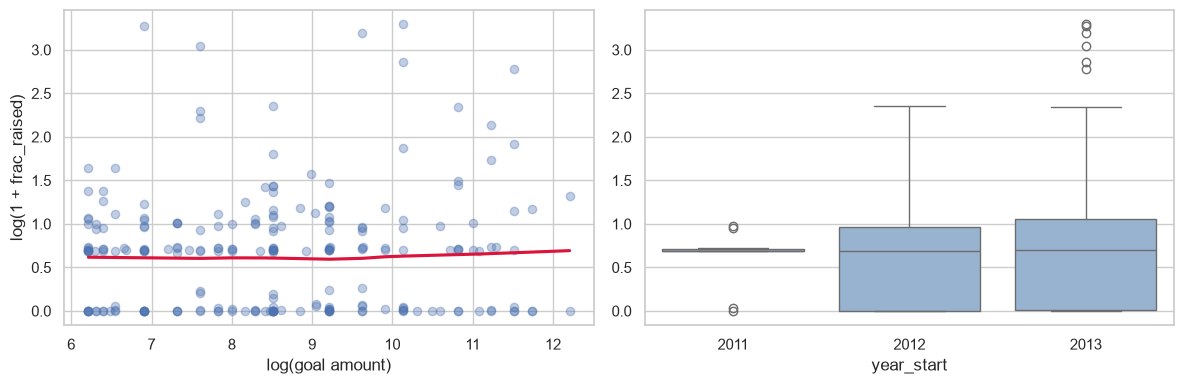

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(x=np.log(raw.amt_goal), y=np.log1p(raw.frac_raised), lowess=True, ax=ax[0],
            scatter_kws=dict(alpha=.35), line_kws=dict(color="crimson"))
ax[0].set_xlabel("log(goal amount)"); ax[0].set_ylabel("log(1 + frac_raised)")
sns.boxplot(x=raw.year_start, y=np.log1p(raw.frac_raised), ax=ax[1], color="#8fb3d9"); ax[1].set_ylabel("")
plt.tight_layout(); plt.savefig(f"{FIG}/03_goal_year.png", dpi=150); plt.show()

In [8]:
print(raw.state.value_counts().head(10))
print("Distinct states:", raw.state.nunique())
print("\nDelivery (observed only for", raw.delivery.notna().sum(), "campaigns):\n", raw.delivery.value_counts())

state
California        50
New York          24
Texas             14
Florida           13
Washington        10
North Carolina     9
Pennsylvania       9
Massachusetts      6
Arizona            6
New Jersey         5
Name: count, dtype: int64
Distinct states: 43

Delivery (observed only for 53 campaigns):
 delivery
1.0    41
0.0     9
0.5     3
Name: count, dtype: int64


## 2. Pre-processing

* `cid` is an identifier — dropped.
* `delivery` is observed only for a minority of campaigns **and is determined after funding** — using it to predict
  funding would be look-ahead leakage, so it is excluded from the predictors.
* `amt_goal` is log-transformed (range $500–$200,000).
* `state` has many levels, most with a handful of campaigns; with n = 224 we keep California and New York and pool the rest.
* `year_start` → dummies for 2012 and 2013 (2011 base).
* The few missing `fixed_fund` / `iot_plus` values are imputed with the mode *inside* the model pipelines.
* Target: `y = log(1 + frac_raised)`. The raw target is extremely right-skewed (mean ≫ median, max ≈ 26× goal), so
  squared-error models on the raw scale are dominated by a handful of outliers. `log1p` keeps zero-raised campaigns and
  compresses the tail.

In [9]:
def make_features(r):
    return pd.DataFrame({
        "pre_order_perk": r.pre_order_perk,
        "log_goal": np.log(r.amt_goal),
        "tech_campaign": r.tech_campaign,
        "sbiz_campaign": r.sbiz_campaign,
        "fixed_fund": r.fixed_fund,
        "iot_plus": r.iot_plus,
        "state_CA": (r.state == "California").astype(int),
        "state_NY": (r.state == "New York").astype(int),
        "year_2012": (r.year_start == 2012).astype(int),
        "year_2013": (r.year_start == 2013).astype(int),
    })

df = make_features(raw)
FEATURES = list(df.columns)
X = df.values
y_raw = raw.frac_raised.values
y = np.log1p(y_raw)
assert "delivery" not in FEATURES and "cid" not in FEATURES
print(df.shape)

(224, 10)


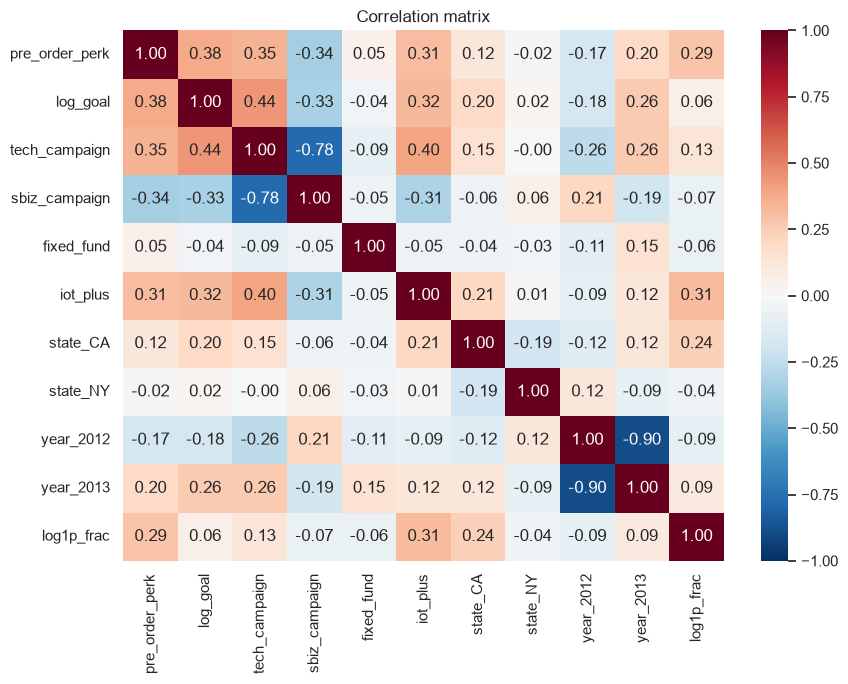

In [10]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.assign(log1p_frac=y).corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix"); plt.tight_layout(); plt.savefig(f"{FIG}/04_correlations.png", dpi=150); plt.show()

### 2b. Why de-duplication matters: leakage in cross-validation
On the original 439 rows we compare ordinary shuffled 10-fold CV with **GroupKFold by `cid`** (all copies of a campaign
kept in the same fold). If a model looks much better under shuffled CV, it is memorising duplicated campaigns,
not learning anything that generalises to a new campaign.

In [11]:
X_all = make_features(raw_all).values
y_all = np.log1p(raw_all.frac_raised.values)
leak_models = {
    "OLS": make_pipeline(SimpleImputer(strategy="most_frequent"), StandardScaler(), LinearRegression()),
    "Random Forest": make_pipeline(SimpleImputer(strategy="most_frequent"),
                                   RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED)),
    "Gradient Boosting": make_pipeline(SimpleImputer(strategy="most_frequent"),
                                       GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                                 subsample=0.7, random_state=SEED)),
}
leak_rows = []
for name, m in leak_models.items():
    r_shuf = cross_validate(m, X_all, y_all, cv=KFold(10, shuffle=True, random_state=SEED), scoring="r2", n_jobs=-1)
    r_grp = cross_validate(m, X_all, y_all, cv=GroupKFold(10), groups=raw_all.cid, scoring="r2", n_jobs=-1)
    leak_rows.append({"model": name, "CV R2 – shuffled rows (439)": r_shuf["test_score"].mean(),
                      "CV R2 – grouped by campaign (439)": r_grp["test_score"].mean()})
leak_table = pd.DataFrame(leak_rows).set_index("model")
display(leak_table.round(3))

,CV R2 – shuffled rows (439),CV R2 – grouped by campaign (439)
model,,
OLS,0.121,-0.402
Random Forest,0.514,-0.966
Gradient Boosting,0.514,-1.687


### Train / test split
With only 224 campaigns a single split is noisy, so the 20 % hold-out is used only as a **final** check. Model
comparison relies on **nested cross-validation** (inner 5-fold for tuning, outer 10-fold × 3 repeats for scoring) on the
training set. The split is stratified on quintiles of the target so both sets contain zeros and extreme successes.

In [12]:
strata = pd.qcut(y, 5, labels=False, duplicates="drop")
X_tr, X_te, y_tr, y_te, yraw_tr, yraw_te = train_test_split(X, y, y_raw, test_size=0.2, random_state=SEED, stratify=strata)
print("train:", X_tr.shape, " test:", X_te.shape)

inner_cv = KFold(5, shuffle=True, random_state=SEED)
outer_cv = RepeatedKFold(n_splits=10, n_repeats=3, random_state=SEED)

train: (179, 10)  test: (45, 10)


## 3. Candidate models and hyper-parameter grids

| Model | Why it is a candidate with n ≈ 180 training campaigns | Hyper-parameters tuned |
|---|---|---|
| Mean (dummy) | floor every model must beat | – |
| OLS | interpretable, 11 parameters ⇒ ~16 obs per parameter | – |
| OLS + pairwise interactions | tests whether interactions matter; 56 parameters ⇒ ~3 obs per parameter, high over-fitting risk | – |
| Ridge | shrinks correlated coefficients (tech / iot / pre-order) | `alpha` |
| Lasso | shrinkage + variable selection | `alpha` |
| Elastic Net | mix of both | `alpha`, `l1_ratio` |
| Huber | robust loss, down-weights extreme campaigns | `epsilon`, `alpha` |
| Random Forest | non-linearities / interactions without specification | `max_depth`, `min_samples_leaf`, `max_features` |
| Gradient Boosting | same, usually more accurate than RF | `learning_rate`, `n_estimators`, `max_depth`, `subsample` |

Tree grids are deliberately restricted to shallow trees / large leaves: with ~180 rows deep trees memorise noise.

In [13]:
def lin(model, poly=False):
    steps = [SimpleImputer(strategy="most_frequent")]
    if poly:
        steps.append(PolynomialFeatures(2, interaction_only=True, include_bias=False))
    return make_pipeline(*steps, StandardScaler(), model)

def tree(model):
    return make_pipeline(SimpleImputer(strategy="most_frequent"), model)

alphas = np.logspace(-4, 1, 30)
CANDIDATES = {
    "Mean (dummy)":      (make_pipeline(DummyRegressor()), {}),
    "OLS":               (lin(LinearRegression()), {}),
    "OLS + interactions": (lin(LinearRegression(), poly=True), {}),
    "Ridge":             (lin(Ridge()), {"ridge__alpha": np.logspace(-2, 3, 30)}),
    "Lasso":             (lin(Lasso(max_iter=50000)), {"lasso__alpha": alphas}),
    "Elastic Net":       (lin(ElasticNet(max_iter=50000)), {"elasticnet__alpha": alphas,
                                                             "elasticnet__l1_ratio": [.1, .3, .5, .7, .9]}),
    "Huber":             (lin(HuberRegressor(max_iter=2000)), {"huberregressor__epsilon": [1.1, 1.35, 1.75, 2.5],
                                                               "huberregressor__alpha": [1e-4, 1e-2, 1, 10]}),
    "Random Forest":     (tree(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1)),
                          {"randomforestregressor__max_depth": [3, 5, None],
                           "randomforestregressor__min_samples_leaf": [5, 10, 20],
                           "randomforestregressor__max_features": [0.33, 0.66, 1.0]}),
    "Gradient Boosting": (tree(GradientBoostingRegressor(random_state=SEED)),
                          {"gradientboostingregressor__learning_rate": [0.01, 0.05, 0.1],
                           "gradientboostingregressor__n_estimators": [100, 300],
                           "gradientboostingregressor__max_depth": [1, 2, 3],
                           "gradientboostingregressor__subsample": [0.7, 1.0]}),
}
# Complexity ranking for the 1-SE rule = effective number of free parameters: Lasso sets coefficients exactly to zero,
# so at its CV alpha it is sparser than OLS; Ridge / EN / Huber keep all 10 features (shrunk).
COMPLEXITY = {"Mean (dummy)": 0, "Lasso": 1, "OLS": 2, "Ridge": 2, "Elastic Net": 2, "Huber": 2,
              "OLS + interactions": 3, "Gradient Boosting": 4, "Random Forest": 4}

def tuned(name):
    model, grid = CANDIDATES[name]
    if not grid:
        return model
    return GridSearchCV(model, grid, cv=inner_cv, scoring="neg_root_mean_squared_error", n_jobs=-1)

## 4. Nested cross-validation (honest comparison)
Each outer validation fold holds only ~18 campaigns, so the *average per-fold* R² is biased downward (a fold's own mean
is unknown to the model). We therefore also report a **pooled** out-of-fold R² = 1 − mean(MSE) / Var(y), which compares
each model's error with the variance of the target.

In [14]:
scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
cv_rows, cv_folds = [], {}
for name in CANDIDATES:
    s = cross_validate(tuned(name), X_tr, y_tr, cv=outer_cv, scoring=scoring, n_jobs=-1 if not CANDIDATES[name][1] else 1)
    rmse = -s["test_rmse"]
    cv_folds[name] = rmse
    cv_rows.append({"model": name, "RMSE": rmse.mean(), "RMSE_se": rmse.std(ddof=1) / np.sqrt(len(rmse)),
                    "MAE": -s["test_mae"].mean(), "R2_pooled": 1 - np.mean(rmse ** 2) / np.var(y_tr),
                    "R2_mean_fold": s["test_r2"].mean(), "R2_sd": s["test_r2"].std(ddof=1),
                    "complexity": COMPLEXITY[name]})
    print(f"{name:20s} RMSE={rmse.mean():.4f}  pooled R2={1 - np.mean(rmse ** 2) / np.var(y_tr):.3f}")
cv_table = pd.DataFrame(cv_rows).sort_values("RMSE").reset_index(drop=True)
display(cv_table.round(4))

Mean (dummy)         RMSE=0.6680  pooled R2=-0.017
OLS                  RMSE=0.6356  pooled R2=0.089
OLS + interactions   RMSE=0.7545  pooled R2=-0.399


Ridge                RMSE=0.6308  pooled R2=0.098


Lasso                RMSE=0.6253  pooled R2=0.113


Elastic Net          RMSE=0.6282  pooled R2=0.103


Huber                RMSE=0.6309  pooled R2=0.097


Random Forest        RMSE=0.6321  pooled R2=0.092


Gradient Boosting    RMSE=0.6406  pooled R2=0.066


,model,RMSE,RMSE_se,MAE,R2_pooled,R2_mean_fold,R2_sd,complexity
0,Lasso,0.6253,0.0246,0.4915,0.1126,-0.0048,0.2596,1
1,Elastic Net,0.6282,0.0250,0.4929,0.1034,-0.0127,0.2588,2
2,Ridge,0.6308,0.0246,0.4979,0.0977,-0.0233,0.2586,2
3,Huber,0.6309,0.0247,0.5005,0.0968,-0.0283,0.2656,2
4,Random Forest,0.6321,0.0252,0.5022,0.0922,-0.0331,0.2996,4
5,OLS,0.6356,0.0232,0.5045,0.0886,-0.0622,0.3227,2
6,Gradient Boosting,0.6406,0.0261,0.5065,0.0659,-0.0586,0.3043,4
7,Mean (dummy),0.6680,0.0275,0.5023,-0.0170,-0.1243,0.2025,0
8,OLS + interactions,0.7545,0.0508,0.5727,-0.3990,-0.6752,1.3795,3


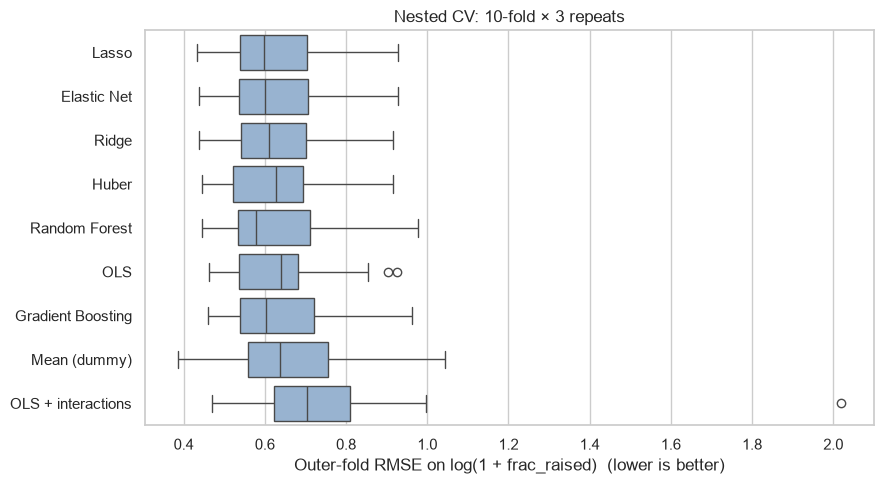

In [15]:
plt.figure(figsize=(9, 5))
order = cv_table.model.tolist()
sns.boxplot(data=pd.DataFrame(cv_folds)[order], orient="h", color="#8fb3d9")
plt.xlabel("Outer-fold RMSE on log(1 + frac_raised)  (lower is better)")
plt.title("Nested CV: 10-fold × 3 repeats")
plt.tight_layout(); plt.savefig(f"{FIG}/05_cv_comparison.png", dpi=150); plt.show()

### Model selection — one-standard-error rule
Differences between the good models are small relative to fold-to-fold noise. We therefore pick the **simplest** model
whose CV RMSE is within one standard error of the best one.

In [16]:
best = cv_table.iloc[0]
threshold = best.RMSE + best.RMSE_se
eligible = cv_table[cv_table.RMSE <= threshold].sort_values(["complexity", "RMSE"])
CHOSEN = eligible.iloc[0].model
print(f"Best CV model: {best.model}  RMSE={best.RMSE:.4f} (+1 SE = {threshold:.4f})")
print("Models within 1 SE:", eligible.model.tolist())
print("Chosen model:", CHOSEN)

Best CV model: Lasso  RMSE=0.6253 (+1 SE = 0.6499)
Models within 1 SE: ['Lasso', 'Elastic Net', 'Ridge', 'Huber', 'OLS', 'Random Forest', 'Gradient Boosting']
Chosen model: Lasso


## 5. Hyper-parameter tuning on the full training set

In [17]:
fitted, best_params = {}, {}
for name in CANDIDATES:
    m = tuned(name).fit(X_tr, y_tr)
    fitted[name] = m.best_estimator_ if hasattr(m, "best_estimator_") else m
    if hasattr(m, "best_params_"):
        best_params[name] = {k.split("__")[1]: (float(v) if isinstance(v, (float, np.floating)) else v)
                             for k, v in m.best_params_.items()}
        print(f"{name:18s}", best_params[name])

Ridge              {'alpha': 62.10169418915616}
Lasso              {'alpha': 0.05736152510448681}


Elastic Net        {'alpha': 0.08531678524172814, 'l1_ratio': 0.7}
Huber              {'alpha': 10, 'epsilon': 2.5}


Random Forest      {'max_depth': None, 'max_features': 0.33, 'min_samples_leaf': 5}


Gradient Boosting  {'learning_rate': 0.01, 'max_depth': 1, 'n_estimators': 300, 'subsample': 1.0}


### Validation curves — how the key hyper-parameters trade off bias and variance

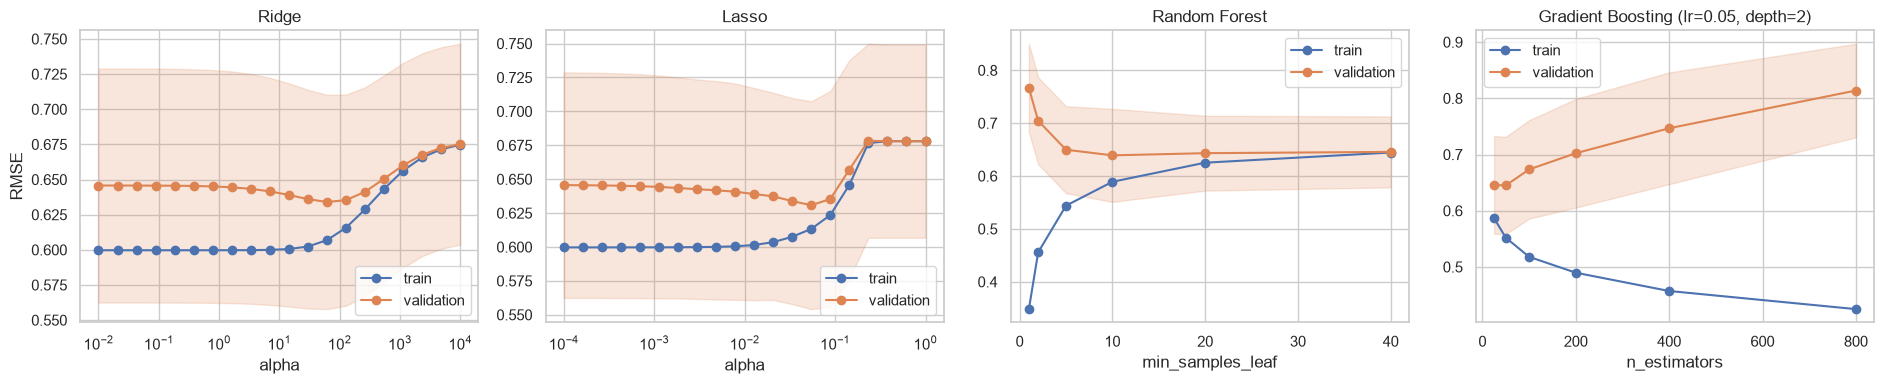

In [18]:
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
def vc(a, est, pname, prange, title, log=False):
    tr, va = validation_curve(est, X_tr, y_tr, param_name=pname, param_range=prange, cv=inner_cv,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
    a.plot(prange, -tr.mean(1), "o-", label="train"); a.plot(prange, -va.mean(1), "o-", label="validation")
    a.fill_between(prange, -va.mean(1) - va.std(1), -va.mean(1) + va.std(1), alpha=.2, color="C1")
    if log: a.set_xscale("log")
    a.set_title(title); a.set_xlabel(pname.split("__")[1]); a.legend()
vc(ax[0], lin(Ridge()), "ridge__alpha", np.logspace(-2, 4, 20), "Ridge", log=True)
vc(ax[1], lin(Lasso(max_iter=50000)), "lasso__alpha", np.logspace(-4, 0, 20), "Lasso", log=True)
vc(ax[2], tree(RandomForestRegressor(n_estimators=300, random_state=SEED)), "randomforestregressor__min_samples_leaf",
   [1, 2, 5, 10, 20, 40], "Random Forest")
vc(ax[3], tree(GradientBoostingRegressor(learning_rate=0.05, max_depth=2, random_state=SEED)),
   "gradientboostingregressor__n_estimators", [25, 50, 100, 200, 400, 800], "Gradient Boosting (lr=0.05, depth=2)")
ax[0].set_ylabel("RMSE")
plt.tight_layout(); plt.savefig(f"{FIG}/06_validation_curves.png", dpi=150); plt.show()

### Learning curves — is the sample large enough?

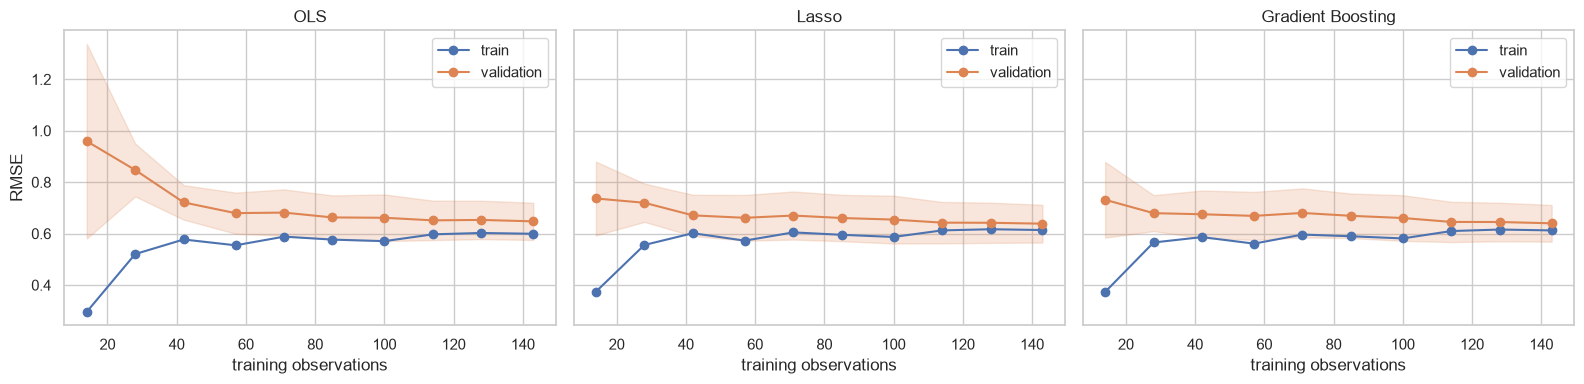

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for a, name in zip(ax, ["OLS", "Lasso", "Gradient Boosting"]):
    sizes, tr, va = learning_curve(fitted[name], X_tr, y_tr, train_sizes=np.linspace(0.1, 1.0, 10),
                                   cv=RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED),
                                   scoring="neg_root_mean_squared_error", n_jobs=-1)
    a.plot(sizes, -tr.mean(1), "o-", label="train"); a.plot(sizes, -va.mean(1), "o-", label="validation")
    a.fill_between(sizes, -va.mean(1) - va.std(1), -va.mean(1) + va.std(1), alpha=.2, color="C1")
    a.set_title(name); a.set_xlabel("training observations"); a.legend()
ax[0].set_ylabel("RMSE")
plt.tight_layout(); plt.savefig(f"{FIG}/07_learning_curves.png", dpi=150); plt.show()

## 6. Hold-out test performance
Metrics are reported on the modelling scale (log(1+frac)) and back-transformed to the original `frac_raised` scale with
Duan's smearing correction. "Goal hit-rate" is the share of test campaigns correctly classified as reaching / not reaching
their goal (frac ≥ 1) from the regression prediction.

In [20]:
def evaluate(model, name):
    p_tr, p = model.predict(X_tr), model.predict(X_te)
    smear = np.mean(np.exp(y_tr - p_tr))                     # Duan smearing on 1 + frac
    frac_hat = np.exp(p) * smear - 1
    return {"model": name,
            "R2 (log)": r2_score(y_te, p), "RMSE (log)": mean_squared_error(y_te, p) ** .5,
            "MAE (log)": mean_absolute_error(y_te, p),
            "R2 (frac)": r2_score(yraw_te, frac_hat), "MAE (frac)": mean_absolute_error(yraw_te, frac_hat),
            "Median AE (frac)": np.median(np.abs(yraw_te - frac_hat)),
            "Goal hit-rate": np.mean((np.expm1(p) >= 1) == (yraw_te >= 1)),
            "Train R2 (log)": r2_score(y_tr, p_tr)}
test_table = pd.DataFrame([evaluate(fitted[n], n) for n in CANDIDATES]).set_index("model").loc[cv_table.model]
display(test_table.round(3))
print("Baseline goal hit-rate (always predict 'reaches goal'):", round(np.mean(yraw_te >= 1), 3))

,R2 (log),RMSE (log),MAE (log),R2 (frac),MAE (frac),Median AE (frac),Goal hit-rate,Train R2 (log)
model,,,,,,,,
Lasso,0.093,0.671,0.525,0.069,1.609,1.041,0.467,0.172
Elastic Net,0.093,0.671,0.524,0.067,1.609,1.059,0.467,0.169
Ridge,0.098,0.670,0.536,0.080,1.625,0.987,0.511,0.193
Huber,0.105,0.667,0.537,0.091,1.642,1.024,0.533,0.202
Random Forest,0.009,0.702,0.558,0.037,1.654,1.014,0.422,0.291
OLS,0.110,0.665,0.541,0.099,1.638,1.026,0.489,0.205
Gradient Boosting,0.091,0.672,0.528,0.070,1.612,1.008,0.467,0.176
Mean (dummy),-0.002,0.705,0.526,-0.001,1.762,1.413,0.378,0.000
OLS + interactions,-0.610,0.894,0.715,-0.264,2.180,1.187,0.378,0.446


Baseline goal hit-rate (always predict 'reaches goal'): 0.622


In [21]:
# Raw-scale benchmark: OLS fitted directly on frac_raised (justifies the log1p transform)
ols_raw = lin(LinearRegression())
s_raw = cross_validate(ols_raw, X_tr, yraw_tr, cv=outer_cv, scoring={"r2": "r2", "mae": "neg_mean_absolute_error"})
s_log = []
for tr_i, va_i in outer_cv.split(X_tr):
    m = lin(LinearRegression()).fit(X_tr[tr_i], y_tr[tr_i])
    smear = np.mean(np.exp(y_tr[tr_i] - m.predict(X_tr[tr_i])))
    f = np.exp(m.predict(X_tr[va_i])) * smear - 1
    s_log.append((r2_score(yraw_tr[va_i], f), mean_absolute_error(yraw_tr[va_i], f)))
s_log = np.array(s_log)
target_cmp = pd.DataFrame({"CV R2 on frac scale": [s_raw["test_r2"].mean(), s_log[:, 0].mean()],
                           "CV MAE on frac scale": [-s_raw["test_mae"].mean(), s_log[:, 1].mean()],
                           "CV R2 sd": [s_raw["test_r2"].std(), s_log[:, 0].std()]},
                          index=["OLS on raw frac_raised", "OLS on log1p, back-transformed"])
display(target_cmp.round(3))

,CV R2 on frac scale,CV MAE on frac scale,CV R2 sd
OLS on raw frac_raised,-1.252,1.853,2.344
"OLS on log1p, back-transformed",-0.432,1.629,1.052


Lasso: test R2 = 0.093, 95% bootstrap CI [-0.171, 0.272]


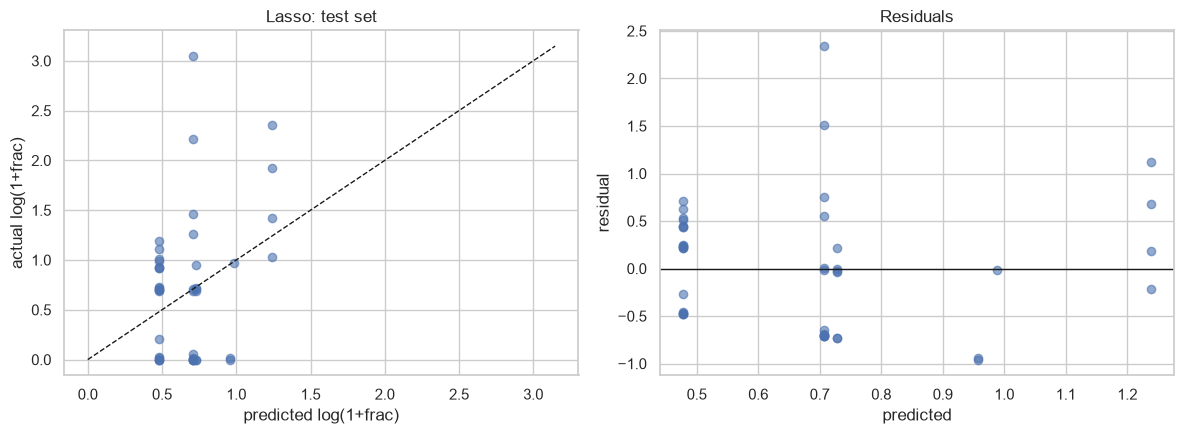

In [22]:
# Bootstrap confidence interval for the chosen model's test R^2
rng = np.random.default_rng(SEED)
p_chosen = fitted[CHOSEN].predict(X_te)
boot = []
for _ in range(2000):
    i = rng.integers(0, len(y_te), len(y_te))
    boot.append(r2_score(y_te[i], p_chosen[i]))
r2_ci = np.percentile(boot, [2.5, 97.5])
print(f"{CHOSEN}: test R2 = {r2_score(y_te, p_chosen):.3f}, 95% bootstrap CI [{r2_ci[0]:.3f}, {r2_ci[1]:.3f}]")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(p_chosen, y_te, alpha=.6); lim = [0, max(y_te.max(), p_chosen.max()) + .1]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set_xlabel("predicted log(1+frac)"); ax[0].set_ylabel("actual log(1+frac)")
ax[0].set_title(f"{CHOSEN}: test set")
ax[1].scatter(p_chosen, y_te - p_chosen, alpha=.6); ax[1].axhline(0, color="k", lw=1)
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("residual"); ax[1].set_title("Residuals")
plt.tight_layout(); plt.savefig(f"{FIG}/08_pred_vs_actual.png", dpi=150); plt.show()

## 7. Variable relevance
### OLS with heteroskedasticity-robust (HC3) standard errors — full sample
Coefficients are on log(1 + frac_raised); `exp(b) − 1` is the % change in (1 + fraction raised).

In [23]:
df_imp = df.fillna(df.mode().iloc[0])
ols = sm.OLS(y, sm.add_constant(df_imp)).fit(cov_type="HC3")
print(ols.summary())
coef = pd.DataFrame({"coef": ols.params, "robust_se": ols.bse, "p_value": ols.pvalues,
                     "pct_effect_on_1+frac": (np.exp(ols.params) - 1) * 100,
                     "ci_low": ols.conf_int()[0], "ci_high": ols.conf_int()[1]}).drop("const")
vif = pd.Series([variance_inflation_factor(sm.add_constant(df_imp).values, i + 1) for i in range(len(FEATURES))],
                index=FEATURES, name="VIF")
coef = coef.join(vif)
display(coef.round(3))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.193
Model:                            OLS   Adj. R-squared:                  0.155
Method:                 Least Squares   F-statistic:                     3.545
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           0.000234
Time:                        13:08:30   Log-Likelihood:                -208.72
No. Observations:                 224   AIC:                             439.4
Df Residuals:                     213   BIC:                             477.0
Df Model:                          10                                         
Covariance Type:                  HC3                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.8529      0.265      3.

,coef,robust_se,p_value,pct_effect_on_1+frac,ci_low,ci_high,VIF
pre_order_perk,0.352,0.095,0.000,42.205,0.166,0.538,1.295
log_goal,-0.066,0.036,0.063,-6.424,-0.136,0.004,1.454
tech_campaign,0.043,0.123,0.729,4.362,-0.198,0.284,3.151
sbiz_campaign,0.118,0.111,0.288,12.482,-0.099,0.335,2.720
fixed_fund,-0.100,0.101,0.325,-9.476,-0.298,0.099,1.092
iot_plus,0.539,0.214,0.012,71.442,0.120,0.958,1.286
state_CA,0.292,0.114,0.011,33.861,0.068,0.515,1.128
state_NY,-0.013,0.175,0.940,-1.305,-0.356,0.330,1.071
year_2012,0.002,0.135,0.988,0.198,-0.263,0.267,5.324
year_2013,0.074,0.129,0.567,7.649,-0.178,0.326,5.493


,OLS,Ridge,Lasso,Elastic Net,Huber
pre_order_perk,0.178,0.127,0.115,0.111,0.161
log_goal,-0.066,-0.027,-0.000,-0.000,-0.053
tech_campaign,0.014,0.009,0.000,0.000,0.004
sbiz_campaign,0.044,0.020,0.000,0.000,0.042
fixed_fund,-0.047,-0.032,-0.000,-0.000,-0.037
iot_plus,0.147,0.109,0.090,0.087,0.127
state_CA,0.143,0.112,0.102,0.099,0.144
state_NY,-0.000,-0.002,-0.000,-0.000,-0.016
year_2012,-0.058,-0.033,-0.000,-0.000,-0.049
year_2013,-0.002,0.019,0.000,0.000,-0.001


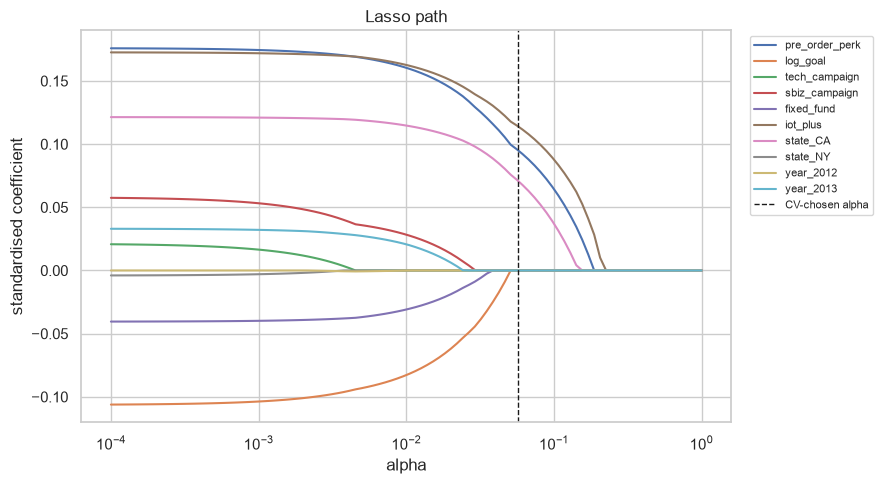

In [24]:
# Standardised coefficients from the regularised models fitted on the training set
std_coefs = pd.DataFrame({n: fitted[n][-1].coef_ for n in ["OLS", "Ridge", "Lasso", "Elastic Net", "Huber"]}, index=FEATURES)
display(std_coefs.round(3))

Xs = StandardScaler().fit_transform(df_imp)
alphas_path, paths, _ = lasso_path(Xs, y, alphas=np.logspace(-4, 0, 100))
plt.figure(figsize=(9, 5))
for j, f in enumerate(FEATURES):
    plt.plot(alphas_path, paths[j], label=f)
if "Lasso" in best_params:
    plt.axvline(best_params["Lasso"]["alpha"], color="k", ls="--", lw=1, label="CV-chosen alpha")
plt.xscale("log"); plt.xlabel("alpha"); plt.ylabel("standardised coefficient"); plt.title("Lasso path")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/09_lasso_path.png", dpi=150); plt.show()

,Lasso,Ridge,Random Forest,Gradient Boosting
iot_plus,0.0707,0.0828,0.0660,0.0727
pre_order_perk,0.0456,0.0516,0.0642,0.0464
log_goal,0.0000,0.0305,-0.0412,0.0000
tech_campaign,0.0000,-0.0029,0.0044,0.0000
sbiz_campaign,0.0000,0.0080,0.0088,0.0000
fixed_fund,0.0000,0.0074,0.0031,0.0000
state_NY,0.0000,0.0004,0.0014,0.0000
year_2012,0.0000,-0.0178,-0.0344,-0.0012
year_2013,0.0000,-0.0087,-0.0265,0.0000
state_CA,-0.0040,-0.0057,-0.0045,-0.0052


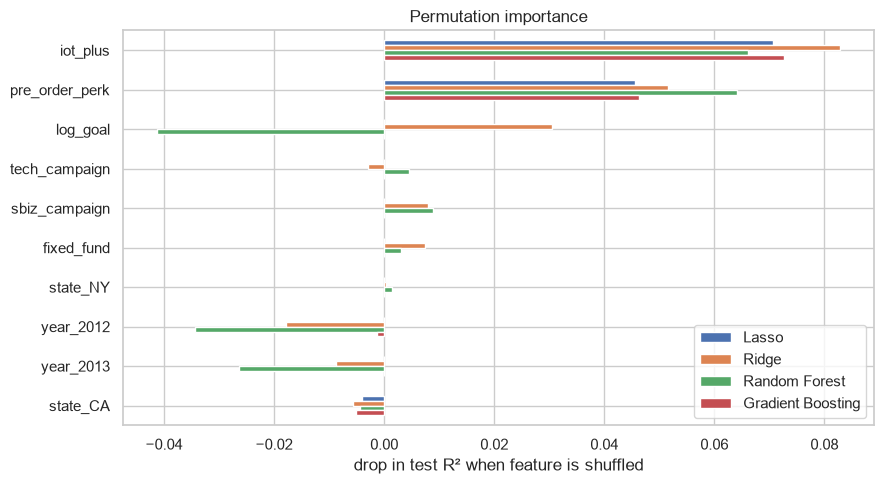

In [25]:
# Permutation importance on the hold-out set (model-agnostic)
imp = {}
for name in dict.fromkeys([CHOSEN, "Ridge", "Random Forest", "Gradient Boosting"]):
    r = permutation_importance(fitted[name], X_te, y_te, n_repeats=50, random_state=SEED, scoring="r2")
    imp[name] = pd.Series(r.importances_mean, index=FEATURES)
imp = pd.DataFrame(imp).sort_values(CHOSEN, ascending=False)
display(imp.round(4))
imp.plot.barh(figsize=(9, 5)).invert_yaxis()
plt.xlabel("drop in test R² when feature is shuffled"); plt.title("Permutation importance")
plt.tight_layout(); plt.savefig(f"{FIG}/10_permutation_importance.png", dpi=150); plt.show()

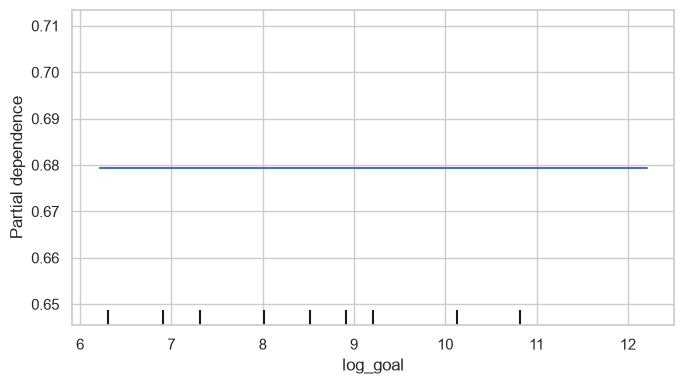

In [26]:
fig, ax = plt.subplots(figsize=(7, 4))
PartialDependenceDisplay.from_estimator(fitted["Gradient Boosting"], X_tr, [FEATURES.index("log_goal")],
                                        feature_names=FEATURES, ax=ax)
plt.tight_layout(); plt.savefig(f"{FIG}/11_pdp_goal.png", dpi=150); plt.show()

### Supplementary: does delivery relate to funding? (descriptive only — not a predictor)

In [27]:
sub = raw.dropna(subset=["delivery"])
display(sub.groupby("delivery").frac_raised.agg(["count", "median", "mean"]).round(2))
display(raw.assign(delivery_known=raw.delivery.notna()).groupby("delivery_known")[["pre_order_perk", "tech_campaign", "iot_plus"]].mean().round(2))

,count,median,mean
delivery,,,
0.0,9,8.97,10.88
0.5,3,2.26,9.76
1.0,41,2.24,3.38


,pre_order_perk,tech_campaign,iot_plus
delivery_known,,,
False,0.33,0.37,0.05
True,1.00,0.74,0.34


In [28]:
cv_table.to_csv(f"{RES}/cv_comparison.csv", index=False)
test_table.to_csv(f"{RES}/test_metrics.csv")
coef.to_csv(f"{RES}/ols_coefficients.csv")
std_coefs.to_csv(f"{RES}/standardised_coefficients.csv")
imp.to_csv(f"{RES}/permutation_importance.csv")
target_cmp.to_csv(f"{RES}/target_transform_comparison.csv")
leak_table.to_csv(f"{RES}/duplicate_leakage.csv")
json.dump({"chosen_model": CHOSEN, "best_cv_model": best.model, "one_se_threshold": threshold,
           "best_params": best_params, "test_r2_ci": list(r2_ci), "n": int(len(df)), "n_rows_raw": int(len(raw_all)), "n_train": int(len(y_tr)),
           "n_test": int(len(y_te)), "ols_r2": ols.rsquared, "ols_adj_r2": ols.rsquared_adj,
           "baseline_hit_rate": float(np.mean(yraw_te >= 1))},
          open(f"{RES}/summary.json", "w"), indent=2, default=float)

## 8. Conclusions

**Sample size.** The 439 rows are only **224 distinct campaigns**: 215 rows are exact copies. On the raw rows, shuffled CV
makes tree ensembles look excellent (R² ≈ 0.51), but grouping folds by campaign shows that this is memorisation of
duplicates (R² < 0). All results below use the 224 unique campaigns (179 train / 45 test).

**Model selection.** In nested CV, every regularised linear model and both tree ensembles land within one standard error
of each other, and all of them beat the mean benchmark. Lasso has the lowest RMSE (0.625 vs 0.668 for the mean; pooled
out-of-fold R² ≈ 0.11) and is also the sparsest, so the 1-SE rule selects it. Trees add no accuracy: the validation curves
push them toward the most constrained settings (depth-1 boosting with a small learning rate, leaves of ≥ 5), which
behave like additive linear models. The 56-parameter interaction model over-fits badly, as expected with ~3 observations
per parameter.

**Predictive power.** It is modest. Test R² for Lasso is 0.09 (95% bootstrap CI −0.17 to 0.27, with only 45 test
campaigns), and in-sample OLS R² is 0.19. As a classifier of "goal reached", no model beats the naive rule "every campaign
succeeds" (62% of test campaigns). The observable characteristics here explain only a small share of why campaigns
succeed. Unobserved factors such as product quality, video, founder network and marketing dominate.

**What matters (robust across OLS, Lasso, Ridge and permutation importance):**
* **Pre-order perk**: +42% in (1 + fraction raised) (p < 0.001). Selected by Lasso, and a top-2 permutation importance in every model.
* **IoT / connected device**: +71% (p = 0.012). The single most important feature out of sample.
* **California**: +34% (p = 0.011). Kept by Lasso, but it adds little out of sample (permutation importance ≈ 0).
* **Goal size**: doubling the goal lowers (1 + frac) by ≈ 4.5% (p = 0.06). Lasso drops it.
* **Not significant**: tech (beyond IoT, which is a subset of tech), small-business, fixed (all-or-nothing) funding,
  New York, start year.